In [1]:
!pip -q install pymupdf transformers accelerate sentence-transformers faiss-cpu pandas matplotlib

In [2]:
import json, re, gc, math, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import fitz

OUT = Path('/content/kuwait_outputs') if Path('/content').exists() else Path('kuwait_outputs')
OUT.mkdir(parents=True, exist_ok=True)
PDF_PATH = None

if PDF_PATH is None:
    found = sorted(Path('/content').glob('*.pdf')) if Path('/content').exists() else sorted(Path('.').glob('*.pdf'))
    if found:
        preferred = [p for p in found if '2026.issue-052' in p.name or 'kuwait' in p.name.lower()]
        PDF_PATH = str((preferred or found)[0])
    else:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError('Please provide the assigned Kuwait IMF PDF.')
        PDF_PATH = next(iter(uploaded))

with fitz.open(PDF_PATH) as pdf:
    pages = []
    for i, page in enumerate(pdf, 1):
        text = page.get_text('text', sort=True)
        text = re.sub(r'©\s*International Monetary Fund\. Not for Redistribution', '', text, flags=re.I)
        text = re.sub(r'(?m)^\s*(?:KUWAIT|INTERNATIONAL MONETARY FUND)\s*$', '', text)
        text = re.sub(r'(?m)^\s*\d{1,2}\s*$', '', text)
        text = re.sub(r'[ \t]+', ' ', text)
        text = re.sub(r'\n{3,}', '\n\n', text).strip()
        if text:
            pages.append({'page': i, 'text': text})

assert pages and 'KUWAIT' in ' '.join(p['text'] for p in pages[:6]).upper(), 'Check the assigned PDF.'
(OUT/'cleaned_pages.json').write_text(json.dumps(pages, indent=2, ensure_ascii=False), encoding='utf-8')
print('Pages with text:', len(pages), '| Characters:', sum(len(p['text']) for p in pages))

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


Saving 1934-7685-002.2026.issue-052-en.pdf to 1934-7685-002.2026.issue-052-en.pdf
Pages with text: 62 | Characters: 146082


Token-aware chunking and source sections

In [3]:
from transformers import AutoTokenizer
MAIN = 'Qwen/Qwen2.5-1.5B-Instruct'
tokenizer = AutoTokenizer.from_pretrained(MAIN)

chunks = []
for p in pages:
    ids = tokenizer.encode(p['text'], add_special_tokens=False)
    for start in range(0, len(ids), 400):
        window = ids[start:start+450]
        if not window: break
        chunks.append({'chunk_id': len(chunks), 'page': p['page'],
                       'token_count': len(window),
                       'text': tokenizer.decode(window, skip_special_tokens=True)})
        if start+450 >= len(ids): break

# Document-order boundaries, using headings found in report text rather than typed content.
HEADINGS = [
    'CONTEXT', 'DEVELOPMENTS, THE OUTLOOK AND RISKS',
    'POLICY DISCUSSIONS', 'A. Fiscal Policy',
    'B. Monetary and Exchange Rate Policies', 'C. Financial Sector Policies',
    'D. Structural Reforms', 'E. Strengthening Statistics', 'STAFF APPRAISAL'
]
heading_lookup = {h.casefold():h for h in HEADINGS}
section_texts = {}; section_pages = {}; active = None
for p in pages:
    if p['page'] < 10: continue
    for line in p['text'].splitlines():
        clean = line.strip()
        if re.match(r'^(?:ANNEX I\.|Annex I\.|Figure 2\. Kuwait:|Table 1\. Kuwait: Selected Economic Indicators, 2021)', clean, flags=re.I):
            active = None
        if clean.casefold() in heading_lookup:
            active = heading_lookup[clean.casefold()]
            section_texts.setdefault(active, '')
            section_pages.setdefault(active, [])
            continue
        if active is not None:
            section_texts[active] += clean + '\n'
            if p['page'] not in section_pages[active]: section_pages[active].append(p['page'])

# Bound the staff-appraisal endpoint before the statistical figures and annexes.
if 'STAFF APPRAISAL' in section_texts:
    part = section_texts['STAFF APPRAISAL']
    section_texts['STAFF APPRAISAL'] = re.split(r'(?m)^Figure 2\. Kuwait:',part)[0]

(OUT/'kuwait_chunks.json').write_text(json.dumps(chunks, indent=2, ensure_ascii=False),encoding='utf-8')
(OUT/'kuwait_sections.json').write_text(json.dumps({'pages':section_pages,'character_counts':{k:len(v) for k,v in section_texts.items()}},indent=2),encoding='utf-8')
print('Chunks:', len(chunks), '| Sections:', len(section_texts))
print('Section headings:', list(section_texts))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Chunks: 140 | Sections: 9
Section headings: ['CONTEXT', 'DEVELOPMENTS, THE OUTLOOK AND RISKS', 'POLICY DISCUSSIONS', 'A. Fiscal Policy', 'B. Monetary and Exchange Rate Policies', 'C. Financial Sector Policies', 'D. Structural Reforms', 'E. Strengthening Statistics', 'STAFF APPRAISAL']


Local LLM summaries

In [4]:
from transformers import AutoModelForCausalLM
model = AutoModelForCausalLM.from_pretrained(
    MAIN, torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map='auto'
).eval()

def generate(messages, mdl, tok, max_new_tokens=160):
    ids = tok.apply_chat_template(messages, tokenize=True, add_generation_prompt=True, return_tensors='pt')
    if hasattr(ids, 'keys'): ids = ids['input_ids']
    ids = ids.to(next(mdl.parameters()).device)
    with torch.inference_mode():
        y = mdl.generate(input_ids=ids, do_sample=False,
                         max_new_tokens=max_new_tokens, pad_token_id=tok.eos_token_id)
    return tok.decode(y[0][ids.shape[1]:], skip_special_tokens=True).strip()

def choose_context(text, budget=1250):
    ids = tokenizer.encode(text, add_special_tokens=False)
    if len(ids) <= budget: return text
    n = budget//3; m = len(ids)//2
    return '\n[...]\n'.join(tokenizer.decode(x,skip_special_tokens=True) for x in
         (ids[:n],ids[m-n//2:m+n//2],ids[-n:]))

def under_100_words(text):
    # Prefer full sentences; use a short word cap only as a final safeguard.
    words = text.split()
    if len(words) < 100: return text
    cut = ' '.join(words[:95]); match = re.search(r'[.!?](?=\s|$)', cut[::-1])
    return cut.rsplit('.',1)[0]+'.' if '.' in cut and len(cut.rsplit('.',1)[0].split())>=35 else cut

summary_path = OUT/'kuwait_section_summaries.json'
if summary_path.exists():
    section_summaries = json.loads(summary_path.read_text(encoding='utf-8'))
else:
    section_summaries = {}
    for section, source in section_texts.items():
        prompt = ('Summarise the Kuwait IMF report section below in ONE paragraph of at most 75 words. '
                  'State economic findings, risks, and policy recommendations only when supported. '
                  'No introductory text or invented numbers.\nSECTION: '+section+'\nEVIDENCE:\n'+choose_context(source))
        answer = generate([{'role':'system','content':'You summarise reports faithfully from evidence only.'},
                           {'role':'user','content':prompt}],model,tokenizer,140)
        section_summaries[section]={'summary':under_100_words(answer),'source_pages':section_pages.get(section,[])}
        summary_path.write_text(json.dumps(section_summaries,indent=2,ensure_ascii=False),encoding='utf-8')
print('Section summaries:',len(section_summaries), '| Word counts:',
      [len(x['summary'].split()) for x in section_summaries.values()])

def executive_table_values(label):
    table = next((p['text'] for p in pages if p['page'] == 6), '')
    for line in table.splitlines():
        if re.match(r'^\s*' + re.escape(label) + r'\s+', line, re.I):
            tail = re.sub(r'^\s*' + re.escape(label) + r'\s+', '', line, flags=re.I)
            values = re.findall(r'-?\d+(?:\.\d+)?', tail)
            if len(values) == 5:
                return [float(x) for x in values]  # years 2023, 2024, 2025, 2026, 2027
    raise ValueError('Missing verified IMF table series: ' + label)

gdp_years = executive_table_values('Real GDP')
cpi_years = executive_table_values('CPI inflation (average)')

exec_path = OUT / 'kuwait_executive_summary.json'
existing_exec = json.loads(exec_path.read_text(encoding='utf-8')) if exec_path.exists() else {}

if existing_exec.get('generation_method') == 'source_checked_bullets_v2':
    executive = existing_exec['executive_summary']
else:
    bullets = [
        f'Growth: Real GDP {"contracted by" if gdp_years[1] < 0 else "expanded by"} {abs(gdp_years[1]):.1f}% in 2024; the IMF projects {gdp_years[3]:.1f}% growth in 2026.',
        f'Inflation: Average CPI inflation was {cpi_years[1]:.1f}% in 2024 and is projected at {cpi_years[3]:.1f}% in 2026.'
    ]
    topics = [
        ('Fiscal policy', 'A. Fiscal Policy', 'fiscal sustainability, deficits, and IMF policy advice'),
        ('Banking stability', 'C. Financial Sector Policies', 'financial system stability and regulatory safeguards'),
        ('External risks', 'DEVELOPMENTS, THE OUTLOOK AND RISKS', 'oil dependence and external risk'),
        ('Structural priorities', 'D. Structural Reforms', 'economic diversification and labor or housing reforms')
    ]
    for heading, section, focus in topics:
        evidence = choose_context(section_texts.get(section, ''), 850)
        if not evidence.strip():
            raise ValueError('Missing source section for executive summary: ' + section)
        prompt = (f'Write just ONE complete factual sentence, 15 to 28 words, about {focus}. '
                  'Use only the source excerpt; avoid numerical facts not clearly given. '
                  'Do not write headings or multiple bullets.\nSOURCE:\n' + evidence)
        response = generate([{'role':'system','content':'Summarise strictly from IMF report evidence.'},
                             {'role':'user','content':prompt}], model, tokenizer, 85)
        clean = re.sub(r'^(?:[-*•]\s*|\d+[.)]\s*)', '', response.strip())
        clean = re.sub(r'\s+', ' ', clean)
        sentence = re.split(r'(?<=[.!?])\s+', clean)[0].strip()
        if len(sentence.split()) > 38:
            sentence = ' '.join(sentence.split()[:38]).rsplit(',',1)[0].rstrip('. ') + '.'
        if not sentence.endswith(('.', '!', '?')):
            sentence += '.'
        if len(sentence.split()) < 6:
            raise ValueError(f'LLM failed to generate usable {heading} evidence; check source.')
        bullets.append(f'{heading}: {sentence}')

    executive = '\n'.join('- ' + x for x in bullets)
    exec_path.write_text(json.dumps({
        'executive_summary': executive,
        'generation_method': 'source_checked_bullets_v2',
        'verified_source': 'IMF Country Report 26/052, PDF page 6 and named staff-report sections'
    }, indent=2, ensure_ascii=False), encoding='utf-8')

assert len([line for line in executive.splitlines() if line.startswith('- ')]) == 6
print('Executive summary saved | Words:', len(executive.split()))
print(executive)


indicator_candidate_path = OUT / 'kuwait_llm_indicator_candidates.json'
if not indicator_candidate_path.exists():
    table_evidence = '\n'.join(
        f'PDF page {p["page"]}: {p["text"][:6000]}'
        for p in pages if p['page'] in [6, 39]
    )
    request = ('Extract Kuwait IMF indicators and return ONLY a JSON object using exactly these keys: '
       'country_name, gdp_growth_forecast_pct, headline_inflation_rate_pct, '
       'central_bank_policy_rate_pct, non_performing_loan_ratio, unemployment_rate_pct, '
       'tier_1_capital_ratio. Use 2026 forecasts for GDP/inflation, and latest clearly '
       'reported observations for the other metrics. All numeric values must be percentages, '
       'not decimal fractions; use null if not explicitly supported.\nEVIDENCE:\n'
       + table_evidence)
    raw = generate([{'role':'system', 'content':'Return strict JSON with no fabricated values.'},
                    {'role':'user','content':request}],model,tokenizer,320)
    candidate = {'raw_response': raw, 'status': 'requires_independent_source_verification'}
    try:
        m = re.search(r'\{[\s\S]*\}', raw)
        candidate['parsed'] = json.loads(m.group()) if m else None
    except (ValueError, AttributeError):
        candidate['parsed'] = None
    indicator_candidate_path.write_text(json.dumps(candidate,indent=2,ensure_ascii=False), encoding='utf-8')
print('LLM indicator candidates saved for independent source validation')

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Section summaries: 9 | Word counts: [81, 90, 91, 99, 77, 86, 88, 86, 87]
Executive summary saved | Words: 152
- Growth: Real GDP contracted by 2.6% in 2024; the IMF projects 3.8% growth in 2026.
- Inflation: Average CPI inflation was 2.9% in 2024 and is projected at 2.1% in 2026.
- Fiscal policy: IMF advises strengthening budget preparation and execution, enhancing flexibility for in-year adjustments, and introducing a contingency reserve to improve fiscal sustainability and reduce procyclicality.
- Banking stability: The banking system remains well-capitalized, liquid, and profitable, with low nonperforming loans and conservative provisioning, underpinned by robust regulatory safeguards.
- External risks: Oil-dependent economies like Kuwait face heightened external risks as their economic resilience hinges on stable oil prices and production levels, which are subject to geopolitical uncertainties and supply chain disruptions.
- Structural priorities: To boost non-oil growth and suppor

strengths and vulnerabilities (local main LLM)

In [5]:
risk_path = OUT / 'kuwait_qualitative_risks.json'

def parse_items(raw, key):
    try:
        match = re.search(r'\{[\s\S]*\}', raw)
        obj = json.loads(match.group()) if match else {}
        values = obj.get(key, [])
        if isinstance(values, list):
            parsed = [x.strip() for x in values if isinstance(x, str) and len(x.strip()) > 12]
            if parsed:
                return parsed[:6]
    except (ValueError, AttributeError):
        pass
    items = []
    for line in raw.splitlines():
        if re.match(r'^\s*(?:[-*•]|\d+[.)])\s*\S', line):
            clean = re.sub(r'^\s*(?:[-*•]|\d+[.)])\s*', '', line).strip()
            if len(clean) > 12:
                items.append(clean)
    return items[:6]

section_keys = ['CONTEXT', 'DEVELOPMENTS, THE OUTLOOK AND RISKS',
                'A. Fiscal Policy', 'C. Financial Sector Policies',
                'D. Structural Reforms', 'STAFF APPRAISAL']
evidence = '\n\n'.join(f'{k}:\n{choose_context(section_texts.get(k, ""), 450)}'
                      for k in section_keys)

risks = {}
for key, description in [('strengths', 'positive economic conditions, buffers and growth drivers'),
                         ('vulnerabilities', 'economic risks, weaknesses and policy challenges')]:
    prompt = (f'List six distinct Kuwait-specific {description} supported by the IMF source. '
              'Write exactly six short NUMBERED lines, not an essay. '
              'Do not invent figures.\nSOURCE:\n' + evidence)
    raw = generate([{'role': 'system', 'content': 'Extract only source-supported economic findings.'},
                    {'role': 'user', 'content': prompt}], model, tokenizer, 300)
    items = parse_items(raw, key)
    llm_count = len(items)

    # Source-sentence fallback if the small LLM fails to follow formatting.
    patterns = (r'\b(strong|robust|stable|rebound|recovery|improv|resilien|surplus|large buffers)\b'
                if key == 'strengths' else
                r'\b(risk|dependen|vulnerab|deficit|shortfall|weaken|challenge|gap|constraint|reform)\b')
    seen = {re.sub(r'\W+', '', x.lower())[:90] for x in items}
    if len(items) < 5:
        for page in pages:
            if not 10 <= page['page'] <= 31:
                continue
            prose = page['text'].replace('\n', ' ')
            for sentence in re.split(r'(?<=[.!?])\s+', prose):
                sentence = sentence.strip()
                if not (45 <= len(sentence) <= 260 and re.search(patterns, sentence, re.I)):
                    continue
                signature = re.sub(r'\W+', '', sentence.lower())[:90]
                if signature not in seen:
                    items.append(sentence)
                    seen.add(signature)
                if len(items) == 6:
                    break
            if len(items) == 6:
                break
    risks[key] = items[:6]
    risks[key + '_method'] = 'LLM bullets' if llm_count >= 5 else 'LLM with source-sentence fallback'
    risks[key + '_raw_response'] = raw

risk_path.write_text(json.dumps(risks, indent=2, ensure_ascii=False), encoding='utf-8')
print('Strengths:', len(risks['strengths']), '| Vulnerabilities:', len(risks['vulnerabilities']))


Strengths: 6 | Vulnerabilities: 6


Local evaluator LLM: model-generated ratings

In [6]:
if 'model' in globals():
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
JUDGE = 'Qwen/Qwen2.5-0.5B-Instruct'
judge_tokenizer = AutoTokenizer.from_pretrained(JUDGE)
judge = AutoModelForCausalLM.from_pretrained(
    JUDGE,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map='auto'
).eval()

score_token_ids = []
for number in range(1, 6):
    encoded = judge_tokenizer.encode(str(number), add_special_tokens=False)
    if len(encoded) != 1:
        raise ValueError('Judge tokenizer cannot constrain score tokens reliably.')
    score_token_ids.append(encoded[0])

def judge_one_score(section, source, summary, metric):
    definitions = {
        'Factual': 'How well is every claim supported by the source evidence?',
        'Completeness': 'How well does the summary cover the main source findings?',
        'Clarity': 'How understandable and concise is the summary?'
    }
    question = (
        f'Evaluate the {metric.lower()} quality of this IMF summary against the source. '
        f'{definitions[metric]} '
        'Use 1=poor, 2=weak, 3=adequate, 4=good, 5=excellent. '
        'Reply with ONE digit only. Do not give every summary the same score automatically.\n'
        'SECTION: ' + section + '\nSOURCE:\n' + choose_context(source, 900)
        + '\nSUMMARY:\n' + summary + '\nSCORE:'
    )
    messages = [
        {'role':'system','content':'You are an IMF source-grounding evaluator. Assess independently.'},
        {'role':'user','content':question}
    ]
    ids = judge_tokenizer.apply_chat_template(
        messages, tokenize=True, add_generation_prompt=True, return_tensors='pt'
    )
    if hasattr(ids, 'keys'):
        ids = ids['input_ids']
    ids = ids.to(next(judge.parameters()).device)
    with torch.inference_mode():
        output = judge.generate(
            input_ids=ids, max_new_tokens=1, do_sample=False,
            prefix_allowed_tokens_fn=lambda batch_id, prefix: score_token_ids,
            pad_token_id=judge_tokenizer.eos_token_id
        )
    response = judge_tokenizer.decode(output[0][ids.shape[1]:], skip_special_tokens=True).strip()
    if response not in ['1','2','3','4','5']:
        return None, response
    return int(response), response

eval_path = OUT / 'kuwait_summary_evaluation.csv'
if eval_path.exists():
    old_eval = pd.read_csv(eval_path)
else:
    old_eval = pd.DataFrame()

required_metrics = ['Factual', 'Completeness', 'Clarity']
valid_cache = (
    len(old_eval) == len(section_summaries)
    and set(required_metrics + ['Section', 'Evaluation_Method']).issubset(old_eval.columns)
    and old_eval['Evaluation_Method'].eq('constrained_model_generation_v2').all()
)
if valid_cache:
    evaluation = old_eval
else:
    records = []
    for section, item in section_summaries.items():
        row = {'Section': section}
        for metric in required_metrics:
            value, raw = judge_one_score(
                section, section_texts.get(section, ''), item['summary'], metric
            )
            row[metric] = value
            row[metric + '_Raw'] = raw
        row['Evaluation_Method'] = 'constrained_model_generation_v2'
        records.append(row)
    evaluation = pd.DataFrame(records)
    evaluation.to_csv(eval_path, index=False)

print(evaluation[['Section'] + required_metrics].to_string(index=False))
missing_scores = evaluation[required_metrics].isna().sum().sum()
print('Missing judge scores:', missing_scores)
print('Judge scores are local model assessments, not verified factual accuracy.')

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

                               Section  Factual  Completeness  Clarity
                               CONTEXT        4             3        3
   DEVELOPMENTS, THE OUTLOOK AND RISKS        3             3        3
                    POLICY DISCUSSIONS        4             3        3
                      A. Fiscal Policy        3             3        3
B. Monetary and Exchange Rate Policies        3             3        3
          C. Financial Sector Policies        4             3        3
                 D. Structural Reforms        4             3        3
           E. Strengthening Statistics        3             3        3
                       STAFF APPRAISAL        4             3        3
Missing judge scores: 0
Judge scores are local model assessments, not verified factual accuracy.


Thematic distribution and six qualitative strengths & risks

In [7]:
patterns={
 'Inflation & Prices':[r'\binflation\b',r'\bCPI\b',r'consumer prices?',r'price stability'],
 'Interest Rates & Credit':[r'interest rates?',r'credit growth',r'\blending\b',r'monetary policy'],
 'Housing & Real Estate':[r'\bhousing\b',r'real estate',r'\bmortgage\b',r'property market'],
 'Banking Capital & Liquidity':[r'bank capital',r'capital adequacy',r'\bliquidity\b',r'Basel III'],
 'Sovereign Debt':[r'government debt',r'public debt',r'sovereign debt',r'bond issuance'],
 'Labor Market Dynamics':[r'\bemployment\b',r'\bunemployment\b',r'labo[u]?r market',r'\bwages?\b'],
 'Systemic Financial Risk':[r'systemic risk',r'financial stability',r'financial sector risk',r'macroprudential']
}
source_text='\n'.join(p['text'] for p in pages)
counts={k:sum(len(re.findall(pat,source_text,re.I)) for pat in pats) for k,pats in patterns.items()}
total=sum(counts.values())
themes=pd.DataFrame([{'Theme':k,'Count':v,'Percentage':round(v/total*100,2) if total else 0}
                     for k,v in counts.items()]).sort_values('Count',ascending=False)
themes.to_csv(OUT/'kuwait_theme_distribution.csv',index=False)
(OUT/'kuwait_theme_distribution.json').write_text(themes.to_json(orient='records',indent=2),encoding='utf-8')

risks=json.loads((OUT/'kuwait_qualitative_risks.json').read_text(encoding='utf-8'))
print(themes.to_string(index=False))
print('Strengths:',len(risks['strengths']),'| Vulnerabilities:',len(risks['vulnerabilities']))

                      Theme  Count  Percentage
      Labor Market Dynamics     72       21.88
         Inflation & Prices     71       21.58
             Sovereign Debt     56       17.02
      Housing & Real Estate     49       14.89
    Interest Rates & Credit     40       12.16
Banking Capital & Liquidity     21        6.38
    Systemic Financial Risk     20        6.08
Strengths: 6 | Vulnerabilities: 6


In [8]:
def page_text(page_num): return next((p['text'] for p in pages if p['page']==page_num),'')
def numeric_table_row(page_num, label, expected_count, year_index):
    # The row name is a schema locator. The numerical answer is read from the PDF.
    for line in page_text(page_num).splitlines():
        if re.match(r'^\s*'+re.escape(label)+r'\s+',line,re.I):
            tail=re.sub(r'^\s*'+re.escape(label)+r'\s+','',line, flags=re.I)
            nums=re.findall(r'(?<![\w])[-+]?\d+(?:\.\d+)?',tail)
            if len(nums)==expected_count: return float(nums[year_index]),line.strip()
    return None,None

schema={
 'gdp_growth_forecast_pct':(6,'Real GDP',5,3,2026),
 'headline_inflation_rate_pct':(6,'CPI inflation (average)',5,3,2026),
 'non_performing_loan_ratio':(39,'Non-performing loans to total gross loans',11,10,2024),
 'tier_1_capital_ratio':(39,'Regulatory Tier 1 capital to risk-weighted assets',11,10,2024)
}
financial={'country_name':'Kuwait'}; audit={}
for key,(page_num,row_label,n,i,year) in schema.items():
    value,line=numeric_table_row(page_num,row_label,n,i)
    financial[key]=value
    audit[key]={'value':value,'year':year,'page':page_num if line else None,
                'source_evidence':line,'status':'source_table_verified' if line else 'missing'}

# A local LLM suggestion is recorded for audit, but is NOT automatically accepted as fact.
for field,terms in {
  'central_bank_policy_rate_pct':['policy rate','discount rate'],
  'unemployment_rate_pct':['unemployment rate','unemployment']}.items():
    excerpts=[]
    for p in pages:
        lines=p['text'].splitlines()
        for i,line in enumerate(lines):
            if any(term in line.lower() for term in terms):
                excerpts.append({'page':p['page'],'text':' '.join(lines[max(0,i-1):i+3])})
    evidence=excerpts[:8]
    raw=generate([{'role':'system','content':'You are a conservative IMF number auditor.'},
      {'role':'user','content':f'Find the most recent clearly reported {field} in this evidence. '
       'Give JSON {"value": number or null, "year": number or null, "page": number or null}. '
       'Do not guess a missing value.\n'+json.dumps(evidence,ensure_ascii=False)}],
      judge,judge_tokenizer,110)
    financial[field]=None
    audit[field]={'value':None,'year':None,'page':None,'status':'missing_unverified',
                  'llm_suggestion_raw':raw,'source_evidence':evidence}

financial={k:financial.get(k) for k in ['country_name','gdp_growth_forecast_pct',
 'headline_inflation_rate_pct','central_bank_policy_rate_pct','non_performing_loan_ratio',
 'unemployment_rate_pct','tier_1_capital_ratio']}
(OUT/'kuwait_financial_data.json').write_text(json.dumps(financial,indent=2),encoding='utf-8')
(OUT/'kuwait_indicator_audit.json').write_text(json.dumps(audit,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(financial,indent=2))
print('Unverified fields are intentionally null; see audit file.')

{
  "country_name": "Kuwait",
  "gdp_growth_forecast_pct": 3.8,
  "headline_inflation_rate_pct": 2.1,
  "central_bank_policy_rate_pct": null,
  "non_performing_loan_ratio": 1.5,
  "unemployment_rate_pct": null,
  "tier_1_capital_ratio": 17.0
}
Unverified fields are intentionally null; see audit file.


Dense-embedding FAISS retrieval with disk caching

In [9]:
from sentence_transformers import SentenceTransformer
import faiss
embedder=SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')
index_file=OUT/'kuwait_faiss.index'
manifest_file=OUT/'kuwait_faiss_manifest.json'
chunk_hash=hashlib.sha256(json.dumps(chunks,ensure_ascii=False).encode()).hexdigest()

valid_cache=False
if index_file.exists() and manifest_file.exists():
    try:
        manifest=json.loads(manifest_file.read_text())
        index=faiss.read_index(str(index_file))
        valid_cache=(manifest.get('chunk_hash')==chunk_hash and index.ntotal==len(chunks))
    except Exception: valid_cache=False
if not valid_cache:
    embeddings=embedder.encode([c['text'] for c in chunks],batch_size=32,
        normalize_embeddings=True,convert_to_numpy=True,show_progress_bar=False).astype('float32')
    index=faiss.IndexFlatIP(embeddings.shape[1]); index.add(embeddings)
    faiss.write_index(index,str(index_file))
    manifest_file.write_text(json.dumps({'chunk_hash':chunk_hash,'count':len(chunks)},indent=2))

def retrieve(question,top_k=3):
    q=embedder.encode([question],normalize_embeddings=True,convert_to_numpy=True).astype('float32')
    scores,idx=index.search(q,min(top_k,index.ntotal))
    return [{'page':chunks[int(j)]['page'],'chunk_id':int(j),'similarity':round(float(s),4),
             'text':chunks[int(j)]['text']} for s,j in zip(scores[0],idx[0]) if j>=0]

questions=[
 'What are the major financial stability risks facing Kuwait?',
 'What fiscal reforms does the IMF recommend?',
 'What does the IMF recommend regarding countercyclical capital buffers?'
]
rag={q:retrieve(q) for q in questions}
(OUT/'kuwait_rag_results.json').write_text(json.dumps(rag,indent=2,ensure_ascii=False),encoding='utf-8')
print('Indexed vectors:',index.ntotal,'| Cached index:',index_file.exists())
for q,matches in rag.items():
    print(q,'=>',[(x['page'],x['similarity']) for x in matches])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Indexed vectors: 140 | Cached index: True
What are the major financial stability risks facing Kuwait? => [(34, 0.693), (34, 0.6591), (13, 0.6587)]
What fiscal reforms does the IMF recommend? => [(17, 0.6914), (40, 0.6326), (45, 0.5997)]
What does the IMF recommend regarding countercyclical capital buffers? => [(24, 0.5355), (23, 0.4765), (29, 0.4594)]


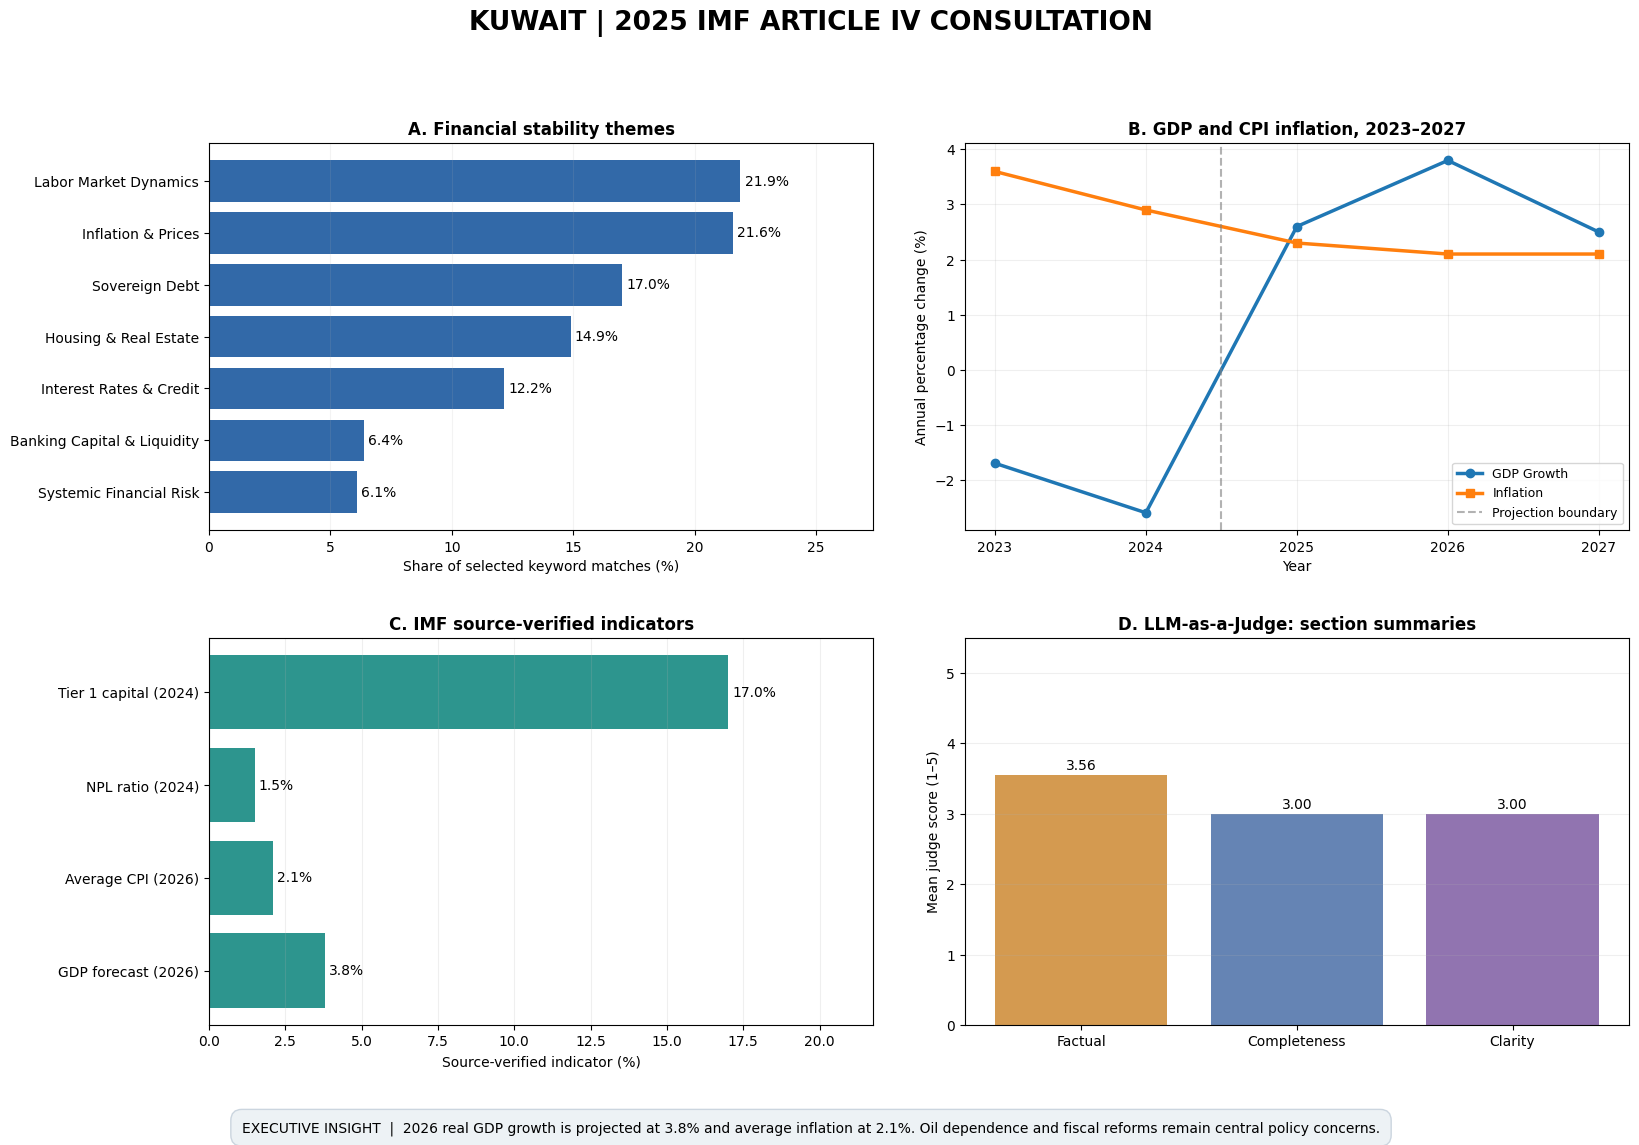

In [11]:
import matplotlib.pyplot as plt
# Directly parsed from the selected-indicators time series in the IMF PDF.
years=list(range(2023,2028))
gdp_line=numeric_table_row(6,'Real GDP',5,3)[1]
inf_line=numeric_table_row(6,'CPI inflation (average)',5,3)[1]
def row_series(line,label):
    if not line: raise ValueError('Missing series in source table: '+label)
    tail=re.sub(r'^\s*'+re.escape(label)+r'\s+','',line,flags=re.I)
    arr=[float(x) for x in re.findall(r'[-+]?\d+(?:\.\d+)?',tail)]
    if len(arr)!=5: raise ValueError('Unexpected series length: '+label)
    return arr
trend_wide=pd.DataFrame({'Year':years,
    'GDP Growth':row_series(gdp_line,'Real GDP'),
    'Inflation':row_series(inf_line,'CPI inflation (average)')})
trend_wide['Period']=np.where(trend_wide['Year']<=2024,'Historical','IMF estimate/projection')
trend_long=pd.melt(trend_wide,id_vars=['Year','Period'],
    value_vars=['GDP Growth','Inflation'],var_name='Indicator',value_name='Percentage')
trend_long.to_csv(OUT/'kuwait_financial_trends.csv',index=False)

fig,axs=plt.subplots(2,2,figsize=(17,12))
fig.patch.set_facecolor('white')
ax=axs[0,0]
t=themes.sort_values('Percentage')
bars=ax.barh(t['Theme'],t['Percentage'],color='#3269a8'); ax.bar_label(bars,fmt='%.1f%%',padding=3)
ax.set_xlim(0,max(t['Percentage'])*1.25); ax.set_xlabel('Share of selected keyword matches (%)')
ax.set_title('A. Financial stability themes',weight='bold');ax.grid(axis='x',alpha=.15)

ax=axs[0,1]
for label,marker in [('GDP Growth','o'),('Inflation','s')]:
    data=trend_long[trend_long['Indicator']==label].sort_values('Year')
    ax.plot(data['Year'],data['Percentage'],marker=marker,linewidth=2.5,label=label)
ax.axvline(2024.5,color='gray',linestyle='--',alpha=.6,label='Projection boundary')
ax.set_xticks(years);ax.set_ylabel('Annual percentage change (%)');ax.set_xlabel('Year')
ax.set_title('B. GDP and CPI inflation, 2023–2027',weight='bold');ax.grid(alpha=.2);ax.legend(fontsize=9)

ax=axs[1,0]
labels={'gdp_growth_forecast_pct':'GDP forecast (2026)',
 'headline_inflation_rate_pct':'Average CPI (2026)',
 'non_performing_loan_ratio':'NPL ratio (2024)',
 'tier_1_capital_ratio':'Tier 1 capital (2024)'}
items=[(v,financial[k]) for k,v in labels.items() if isinstance(financial.get(k),(int,float))]
bars=ax.barh([x[0] for x in items],[x[1] for x in items],color='#2d958e')
ax.bar_label(bars,fmt='%.1f%%',padding=3)
ax.set_xlim(0,max((x[1] for x in items),default=1)*1.28);ax.set_xlabel('Source-verified indicator (%)')
ax.set_title('C. IMF source-verified indicators',weight='bold');ax.grid(axis='x',alpha=.2)

ax=axs[1,1]
metrics=['Factual','Completeness','Clarity']
means=evaluation[metrics].apply(pd.to_numeric,errors='coerce').mean()
bars=ax.bar(metrics,means.values,color=['#d49a50','#6584b4','#9174b0'])
for b,val in zip(bars,means.values):
    if np.isfinite(val): ax.text(b.get_x()+b.get_width()/2,val+.08,f'{val:.2f}',ha='center')
ax.set_ylim(0,5.5);ax.set_ylabel('Mean judge score (1–5)')
ax.set_title('D. LLM-as-a-Judge: section summaries',weight='bold');ax.grid(axis='y',alpha=.2)

fig.suptitle('KUWAIT | 2025 IMF ARTICLE IV CONSULTATION',fontsize=19,weight='bold',y=.99)
fig.text(.5,.055, f'EXECUTIVE INSIGHT  |  2026 real GDP growth is projected at {financial.get("gdp_growth_forecast_pct")}%'
         f' and average inflation at {financial.get("headline_inflation_rate_pct")}%. '
         'Oil dependence and fiscal reforms remain central policy concerns.',ha='center',fontsize=10,
         bbox=dict(boxstyle='round',facecolor='#edf2f5',edgecolor='#cbd5df',pad=.8))
fig.tight_layout(rect=[.02,.095,.99,.945],h_pad=3,w_pad=3)
file=OUT/'kuwait_imf_dashboard.png'
fig.savefig(file,dpi=300,bbox_inches='tight',facecolor='white')
plt.show()


Validation Check

In [12]:
from PIL import Image
required=['cleaned_pages.json','kuwait_chunks.json','kuwait_sections.json',
 'kuwait_section_summaries.json','kuwait_executive_summary.json',
 'kuwait_summary_evaluation.csv','kuwait_theme_distribution.json','kuwait_theme_distribution.csv',
 'kuwait_financial_data.json','kuwait_llm_indicator_candidates.json','kuwait_indicator_audit.json','kuwait_qualitative_risks.json',
 'kuwait_faiss.index','kuwait_faiss_manifest.json','kuwait_rag_results.json',
 'kuwait_financial_trends.csv','kuwait_imf_dashboard.png']
missing=[f for f in required if not (OUT/f).is_file()]
with Image.open(OUT/'kuwait_imf_dashboard.png') as img:
    size=img.size; dpi=img.info.get('dpi',(0,0))
checks={
 'Output files':not missing,
 'Section summaries':len(section_summaries)==9 and all(0<len(v['summary'].split())<100 for v in section_summaries.values()),
 'Financial schema':all(k in financial for k in ['country_name','gdp_growth_forecast_pct','headline_inflation_rate_pct',
                      'central_bank_policy_rate_pct','non_performing_loan_ratio','unemployment_rate_pct','tier_1_capital_ratio']),
 'Seven themes':len(themes)==7,
 '5-7 strengths and risks':all(isinstance(risks.get(k),list) and 5<=len(risks[k])<=7 for k in ['strengths','vulnerabilities']),
 'FAISS aligned':index.ntotal==len(chunks),
 'Long-form trends':len(trend_long)==10,
 'Dashboard 300 DPI':size[0]>=3000 and min(dpi)>=299,
 'Complete judge scores':evaluation[['Factual','Completeness','Clarity']].notna().all().all()
}
print('FINAL STRUCTURAL VALIDATION')
for k,v in checks.items(): print(k+':','PASS' if v else 'CHECK')
print('Missing files:',missing)
print('Missing indicator values:',[k for k,v in financial.items() if k!='country_name' and v is None])
print('Missing evaluator scores:',evaluation[['Factual','Completeness','Clarity']].isna().sum().sum())
print('Financial figures and judge assessments still require critical human review.')
print('OVERALL:', 'PASS' if all(checks.values()) else 'REVIEW REQUIRED')

FINAL STRUCTURAL VALIDATION
Output files: PASS
Section summaries: PASS
Financial schema: PASS
Seven themes: PASS
5-7 strengths and risks: PASS
FAISS aligned: PASS
Long-form trends: PASS
Dashboard 300 DPI: PASS
Complete judge scores: PASS
Missing files: []
Missing indicator values: ['central_bank_policy_rate_pct', 'unemployment_rate_pct']
Missing evaluator scores: 0
Financial figures and judge assessments still require critical human review.
OVERALL: PASS
